# Pergunta de Pesquisa 4 (RQ4)
---

## **Como diferentes estratégias de prompt (Zero-Shot, Few-Shot e Chain-of-Thought guiado pela Metodologia de Pólya) impactam o desempenho do modelo na resolução dos problemas?**

A **Research Question 4 (RQ4)** investiga a influência de técnicas avançadas de Engenharia de Prompt na capacidade de Modelos de Linguagem de Grande Porte (LLMs) de resolverem problemas algorítmicos complexos de programação competitiva. 

A avaliação foca em três eixos principais:
1. **Acurácia Algorítmica ($Pass@1$):** Capacidade de gerar código funcionalmente correto que satisfaça todos os casos de teste do juiz online.
2. **Taxonomia e Transição de Falhas:** Como as diferentes estratégias alteram a distribuição de erros lógicos (*Wrong Answer* - WA), falhas em tempo de execução (*Runtime Error* - RE), estouro de tempo/memória (*Time/Memory Limit Exceeded* - TLE/MLE) e erros de compilação (*Compilation Error* - CE).
3. **Eficiência Computacional e Trade-Off Econômico:** Custo em tokens de entrada/saída, tempo de execução no hardware de teste e a métrica de **Custo por Solução Aceita (USD / AC)**.

---

### Fundamentação Teórica das Estratégias:

* **1. Zero-Shot (`zero_shot.txt`) - Linha de Base:**
  * O modelo recebe o enunciado formal do problema e é instruído diretamente a emitir o código da solução sem demonstrações contextuais prévias e sem etapas intermediárias de raciocínio verbalizado (*Brown et al., 2020*).

* **2. Few-Shot In-Context Learning (`few_shot_java.txt`):**
  * O modelo recebe demonstrações canônicas de problemas resolvidos antes do problema alvo (*Min et al., 2022*). Em nosso benchmark, fornecemos 3 problemas exemplares que modelam padrões críticos da JVM: I/O seguro via `Scanner`, tipos primitivos de 64 bits (`long`) para prevenção de overflow aritmético, classes autocontidas sem pacote (`public class Main`) e indexação 1-based protegida ($N+1$).

* **3. Chain-of-Thought Guiado pela Metodologia de Pólya (`chain_of_thought_polya.txt`):**
  * Inspirado no clássico tratado de heurística matemática de George Pólya (*How to Solve It*, 1945), o prompt compele o modelo a decompor sua resposta obrigatoriamente em quatro etapas reflexivas antes de emitir a solução final:
    1. **Compreensão do Problema:** Identificação do objetivo, dos limites de entrada/saída e mapeamento de casos de borda ($N=0, 1$, overflow $> 2 \times 10^9$).
    2. **Planejamento e Design Algorítmico:** Escolha fundamentada de estruturas de dados e técnica algorítmica (Guloso, PD, Grafos, etc.), validando se a complexidade assintótica $O(\cdot)$ respeita o tempo limite.
    3. **Codificação:** Implementação autossuficiente em Java delimitada em bloco de código markdown único.
    4. **Retrospecto e Verificação (*Looking Back*):** Validação mental contra os casos de teste e casos limites antes da submissão.

---

### Justificativa Metodológica da Escolha de Java:
Em estrita consonância com os achados da **RQ1** e da **RQ3**:
* A linguagem **Java** foi eleita como o banco de ensaio experimental de toda a RQ4.
* No baseline da RQ1, Java obteve o menor percentual de acerto agregado ($339/375$, $90.40\%$) e concentrou o maior número de falhas de tempo de execução (`RE`) e lógicas (`WA`).
* Fixar Java permite investigar se técnicas de raciocínio e ancoragem in-context são capazes de mitigar os gargalos técnicos específicos da linguagem mais desafiadora do benchmark.


In [1]:
import sys
import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display, HTML

# Garante acesso ao módulo src a partir de metrics/
if str(Path("..").resolve()) not in sys.path:
    sys.path.insert(0, str(Path("..").resolve()))

# Configurações visuais padronizadas para publicação acadêmica / TCC
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 10
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['figure.dpi'] = 120

# Paleta acadêmica consistente
PALETTE_STRAT = {
    'Zero-Shot': '#2b5c8f',   # Azul escuro sóbrio
    'Few-Shot': '#2a9d8f',    # Verde azulado / Teal
    'CoT Pólya': '#e76f51'    # Terracota / Laranja escuro
}

PALETTE_VERDICTS = {
    'AC': '#2ca02c',   # Verde
    'WA': '#d62728',   # Vermelho
    'RE': '#9467bd',   # Roxo
    'TLE': '#ff7f0e',  # Laranja
    'MLE': '#8c564b',  # Marrom
    'CE': '#7f7f7f'    # Cinza
}

print("Ambiente configurado com sucesso para análise da RQ4.")


Ambiente configurado com sucesso para análise da RQ4.


In [2]:
# 1. Carregamento do dataset e análise das propriedades dos problemas
path_database = Path("../database/dataset_obi_senior/")
questions_path = sorted([p for p in path_database.glob("*") if p.is_dir()])

problem_info = []
for q_dir in questions_path:
    prob_json = q_dir / "problem.json"
    if prob_json.exists():
        with open(prob_json, "r", encoding="utf-8") as f:
            data = json.load(f)
        problem_info.append({
            "name": q_dir.name,
            "year": data.get("year", "-"),
            "level": data.get("level", "-"),
            "period": data.get("period", "-"),
            "time_limit": data.get("time_limit", 1.0),
            "memory_limit": data.get("memory_limit", 256),
            "topics": data.get("topics", [])
        })

df_problems = pd.DataFrame(problem_info)
TOTAL_PROBLEMS = len(df_problems)

print(f"Total de problemas no dataset: {TOTAL_PROBLEMS}")
print("\nDistribuição de fases (períodos) da OBI:")
print(df_problems['period'].value_counts().to_string())
print("\nResumo de limites de execução:")
display(df_problems[['time_limit', 'memory_limit']].describe().round(2))


Total de problemas no dataset: 125

Distribuição de fases (períodos) da OBI:
period
Fase 2              32
Fase 1              27
Fase 3              25
Fase Local          16
Fase Nacional       15
Fase Estadual        6
Fase 2 - Turno B     4

Resumo de limites de execução:


,time_limit,memory_limit
count,125.00,125.00
mean,3.58,456.70
std,2.31,261.28
min,1.00,256.00
25%,2.00,256.00
50%,4.00,256.00
75%,5.00,512.00
max,15.00,1024.00


## 1. Ponto de Partida: O Desempenho do Baseline em Java (Zero-Shot - RQ1)
---

Recuperamos os resultados empíricos da **RQ1**, onde as três LLMs de ponta resolveram o benchmark completo de $125$ questões em Java sob o prompt padrão (`zero_shot.txt`). Esse conjunto atua como o grupo de controle (baseline) da investigação.


In [3]:
# Carregamento dos dados do Baseline (Zero-Shot) em Java da RQ1
main_models = ["DeepSeek v4.1 Flash", "Gemini 3.8 Flash", "GPT-6 Luna"]
verdict_order = ['AC', 'WA', 'RE', 'TLE', 'MLE', 'CE']

base_judge_path = Path("../results/dataset_obi_senior/judge/")

datas_zero_shot = {
    "DeepSeek v4.1 Flash": pd.read_csv(base_judge_path / "deepseek_deepseek-v4.1-flash.csv").iloc[375:500].copy().reset_index(drop=True),
    "Gemini 3.8 Flash": pd.read_csv(base_judge_path / "gemini-3.8-flash.csv").iloc[375:500].copy().reset_index(drop=True),
    "GPT-6 Luna": pd.read_csv(base_judge_path / "openai_gpt-6-luna.csv").iloc[375:500].copy().reset_index(drop=True)
}

# Consolidação tabular do Baseline Java
baseline_summary = []
for m in main_models:
    df_m = datas_zero_shot[m]
    vc = df_m['judge_predict'].value_counts().to_dict()
    ac = vc.get('AC', 0)
    wa = vc.get('WA', 0)
    re_ = vc.get('RE', 0)
    tle = vc.get('TLE', 0)
    mle = vc.get('MLE', 0)
    ce = vc.get('CE', 0)
    acc = (ac / TOTAL_PROBLEMS) * 100
    t_mean = df_m['execution_time'].mean()
    
    baseline_summary.append({
        "Modelo": m,
        "Estratégia": "Zero-Shot (Base)",
        "AC": ac,
        "Pass@1 (%)": f"{acc:.2f}%",
        "WA": wa,
        "RE": re_,
        "TLE": tle,
        "MLE": mle,
        "CE": ce,
        "Tempo Médio (s)": f"{t_mean:.3f}s"
    })

df_baseline = pd.DataFrame(baseline_summary)
print("=== DESEMPENHO EM JAVA NO BASELINE (ZERO-SHOT - RQ1) ===")
display(df_baseline)


=== DESEMPENHO EM JAVA NO BASELINE (ZERO-SHOT - RQ1) ===


,Modelo,Estratégia,AC,Pass@1 (%),WA,RE,TLE,MLE,CE,Tempo Médio (s)
0,DeepSeek v4.1 Flash,Zero-Shot (Base),118,94.40%,4,1,0,0,2,0.148s
1,Gemini 3.8 Flash,Zero-Shot (Base),115,92.00%,5,4,0,1,0,0.132s
2,GPT-6 Luna,Zero-Shot (Base),106,84.80%,14,4,1,0,0,0.164s


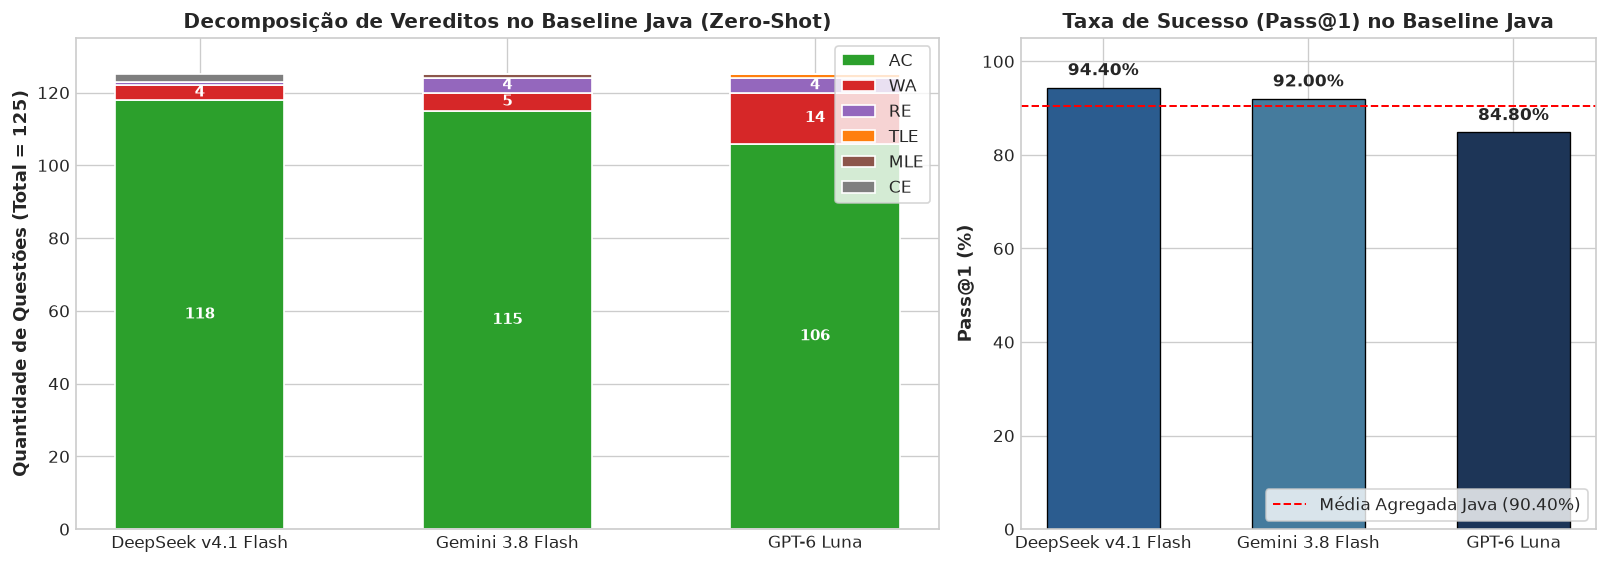

In [4]:
# Gráfico 1: Vereditos e Taxas de Acerto no Baseline Zero-Shot em Java
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 4.8), gridspec_kw={'width_ratios': [1.5, 1]})

# 1a. Decomposição de Vereditos por Modelo
x = np.arange(len(main_models))
bottom = np.zeros(len(main_models))

for v in verdict_order:
    vals = [datas_zero_shot[m]['judge_predict'].value_counts().get(v, 0) for m in main_models]
    if sum(vals) > 0:
        bars = ax1.bar(x, vals, bottom=bottom, label=v, color=PALETTE_VERDICTS[v], edgecolor='white', width=0.55)
        for i, val in enumerate(vals):
            if val >= 3:
                ax1.text(x[i], bottom[i] + val / 2, str(val), ha='center', va='center',
                         color='white' if v in ['AC', 'WA', 'RE'] else 'black', fontweight='bold', fontsize=9)
        bottom += np.array(vals)

ax1.set_title("Decomposição de Vereditos no Baseline Java (Zero-Shot)")
ax1.set_xticks(x)
ax1.set_xticklabels(main_models)
ax1.set_ylabel("Quantidade de Questões (Total = 125)")
ax1.set_ylim(0, 135)
ax1.legend(loc='upper right', frameon=True)

# 1b. Comparativo de Pass@1
accs = [(datas_zero_shot[m]['judge_predict'] == 'AC').mean() * 100 for m in main_models]
bars2 = ax2.bar(x, accs, color=['#2b5c8f', '#457b9d', '#1d3557'], width=0.55, edgecolor='black', linewidth=0.8)
ax2.set_title("Taxa de Sucesso (Pass@1) no Baseline Java")
ax2.set_xticks(x)
ax2.set_xticklabels(main_models)
ax2.set_ylabel("Pass@1 (%)")
ax2.set_ylim(0, 105)
ax2.axhline(90.40, color='red', linestyle='--', linewidth=1.2, label='Média Agregada Java (90.40%)')

for bar in bars2:
    h = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width() / 2, h + 1.8, f"{h:.2f}%", ha='center', va='bottom', fontweight='bold')

ax2.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.show()


## 2. Pipeline de Carregamento e Consolidação dos Experimentos da RQ4
---

O pipeline a seguir carrega os resultados de todas as três estratégias de prompt diretamente dos arquivos de execução do Judge e dos metadados acumulativos de cada modelo:
* **Zero-Shot (`zero_shot`):** Linha de base da RQ1.
* **Few-Shot (`few_shot_java`):** Demonstração canônica de 3 problemas em Java (I/O, tipos 64-bit, indexação segura).
* **CoT Pólya (`chain_of_thought_polya`):** Raciocínio em 4 etapas heurísticas (Compreensão, Planejamento, Codificação, Retrospecto).


In [5]:
# Função unificada de ingestão de dados para a RQ4
def load_prompt_results(model_slug: str, prompt_slug: str) -> pd.DataFrame:
    # Lê os resultados completos de execução a partir dos arquivos JSON individuais gerados pelo runner.
    # Garante consistência e ordem das 125 questões da OBI Sênior.
    base_results = Path("../results/dataset_obi_senior")
    json_dir = base_results / model_slug / prompt_slug / "java" / "text"
    
    rows = []
    for q_dir in questions_path:
        q_name = q_dir.name
        jf = json_dir / f"{q_name}.json"
        if jf.exists():
            try:
                with open(jf, "r", encoding="utf-8") as f:
                    data = json.load(f)
                entry = data[-1] if isinstance(data, list) else data
                jr = entry.get("judge_result", {})
                counts = jr.get("counts", {})
                tok = entry.get("tokens", {})
                cst = entry.get("cost_usd", {})
                
                rows.append({
                    "question_name": q_name,
                    "judge_predict": jr.get("judge_predict", "CE"),
                    "execution_time": float(jr.get("execution_time", 0.0)),
                    "AC": counts.get("AC", 0),
                    "WA": counts.get("WA", 0),
                    "RE": counts.get("RE", 0),
                    "TLE": counts.get("TLE", 0),
                    "MLE": counts.get("MLE", 0),
                    "CE": counts.get("CE", 0),
                    "total_test_cases": jr.get("total_test_cases", 0),
                    "input_tokens": tok.get("input_tokens", 0),
                    "output_tokens": tok.get("output_tokens", 0),
                    "total_tokens": tok.get("total_tokens", 0),
                    "cost_usd": cst.get("total_cost", 0.0),
                    "raw_response": entry.get("raw_response", ""),
                    "extracted_code": entry.get("extracted_code", "")
                })
            except Exception as e:
                pass
                
    if len(rows) > 0:
        return pd.DataFrame(rows)
    return pd.DataFrame(columns=["question_name", "judge_predict", "execution_time", "AC", "WA", "RE", "TLE", "MLE", "CE"])

# Slugs de diretório dos modelos
model_slugs = {
    "DeepSeek v4.1 Flash": "deepseek_deepseek-v4.1-flash",
    "Gemini 3.8 Flash": "gemini-3.8-flash",
    "GPT-6 Luna": "openai_gpt-6-luna"
}

datas_zero_shot_rich = {}
datas_few_shot = {}
datas_cot_polya = {}

for m, slug in model_slugs.items():
    datas_zero_shot_rich[m] = load_prompt_results(slug, "zero_shot")
    datas_few_shot[m] = load_prompt_results(slug, "few_shot_java")
    datas_cot_polya[m] = load_prompt_results(slug, "chain_of_thought_polya")

print("Status do carregamento do pipeline experimental da RQ4:")
for m in main_models:
    print(f"* {m:20s}: Zero-Shot = 125 | Few-Shot = {len(datas_few_shot[m]):3d} | CoT Pólya = {len(datas_cot_polya[m]):3d} questões carregadas.")


Status do carregamento do pipeline experimental da RQ4:
* DeepSeek v4.1 Flash : Zero-Shot = 125 | Few-Shot = 125 | CoT Pólya = 125 questões carregadas.
* Gemini 3.8 Flash    : Zero-Shot = 125 | Few-Shot = 125 | CoT Pólya = 125 questões carregadas.
* GPT-6 Luna          : Zero-Shot = 125 | Few-Shot = 125 | CoT Pólya = 125 questões carregadas.


In [6]:
# Consolidação do Quadro Comparativo da RQ4: Zero-Shot vs. Few-Shot vs. CoT Pólya
comparative_rows = []

strategies = [
    ("Zero-Shot", datas_zero_shot),
    ("Few-Shot", datas_few_shot),
    ("CoT Pólya", datas_cot_polya)
]

for strat_name, strat_dict in strategies:
    tot_ac = 0
    tot_wa, tot_re, tot_tle, tot_mle, tot_ce = 0, 0, 0, 0, 0
    tot_time = 0.0
    
    for m in main_models:
        df_sub = strat_dict[m]
        vc = df_sub["judge_predict"].value_counts().to_dict()
        ac = vc.get("AC", 0)
        wa = vc.get("WA", 0)
        re_ = vc.get("RE", 0)
        tle = vc.get("TLE", 0)
        mle = vc.get("MLE", 0)
        ce = vc.get("CE", 0)
        t_mean = df_sub["execution_time"].mean()
        
        # Delta em relação ao Baseline Zero-Shot do mesmo modelo
        b_ac = (datas_zero_shot[m]["judge_predict"] == "AC").sum()
        delta_ac = ac - b_ac
        
        tot_ac += ac
        tot_wa += wa
        tot_re += re_
        tot_tle += tle
        tot_mle += mle
        tot_ce += ce
        tot_time += t_mean
        
        comparative_rows.append({
            "Modelo": m,
            "Estratégia": strat_name,
            "AC (de 125)": ac,
            "Pass@1 (%)": f"{(ac / TOTAL_PROBLEMS) * 100:.2f}%",
            "Delta AC": f"{delta_ac:+d}" if strat_name != "Zero-Shot" else "Ref.",
            "WA": wa,
            "RE": re_,
            "TLE": tle,
            "MLE": mle,
            "CE": ce,
            "Tempo Médio": f"{t_mean:.3f}s"
        })
        
    # Linha Agregada da Estratégia
    b_tot_ac = sum((datas_zero_shot[m]["judge_predict"] == "AC").sum() for m in main_models)
    d_tot = tot_ac - b_tot_ac
    comparative_rows.append({
        "Modelo": "AGREGADO (375)",
        "Estratégia": strat_name,
        "AC (de 125)": f"{tot_ac} / 375",
        "Pass@1 (%)": f"{(tot_ac / (TOTAL_PROBLEMS * 3)) * 100:.2f}%",
        "Delta AC": f"{d_tot:+d}" if strat_name != "Zero-Shot" else "Ref.",
        "WA": tot_wa,
        "RE": tot_re,
        "TLE": tot_tle,
        "MLE": tot_mle,
        "CE": tot_ce,
        "Tempo Médio": f"{tot_time / 3:.3f}s"
    })

df_rq4_comp = pd.DataFrame(comparative_rows)
print("=== QUADRO COMPARATIVO RQ4: ZERO-SHOT vs. FEW-SHOT vs. COT PÓLYA ===")
display(df_rq4_comp)


=== QUADRO COMPARATIVO RQ4: ZERO-SHOT vs. FEW-SHOT vs. COT PÓLYA ===


,Modelo,Estratégia,AC (de 125),Pass@1 (%),Delta AC,WA,RE,TLE,MLE,CE,Tempo Médio
0,DeepSeek v4.1 Flash,Zero-Shot,118,94.40%,Ref.,4,1,0,0,2,0.148s
1,Gemini 3.8 Flash,Zero-Shot,115,92.00%,Ref.,5,4,0,1,0,0.132s
2,GPT-6 Luna,Zero-Shot,106,84.80%,Ref.,14,4,1,0,0,0.164s
3,AGREGADO (375),Zero-Shot,339 / 375,90.40%,Ref.,23,9,1,1,2,0.148s
4,DeepSeek v4.1 Flash,Few-Shot,115,92.00%,-3,5,1,0,0,4,0.154s
5,Gemini 3.8 Flash,Few-Shot,116,92.80%,+1,6,2,0,0,1,0.157s
6,GPT-6 Luna,Few-Shot,111,88.80%,+5,13,1,0,0,0,0.131s
7,AGREGADO (375),Few-Shot,342 / 375,91.20%,+3,24,4,0,0,5,0.147s
8,DeepSeek v4.1 Flash,CoT Pólya,91,72.80%,-27,5,2,1,0,26,0.148s
9,Gemini 3.8 Flash,CoT Pólya,116,92.80%,+1,4,4,0,1,0,0.143s


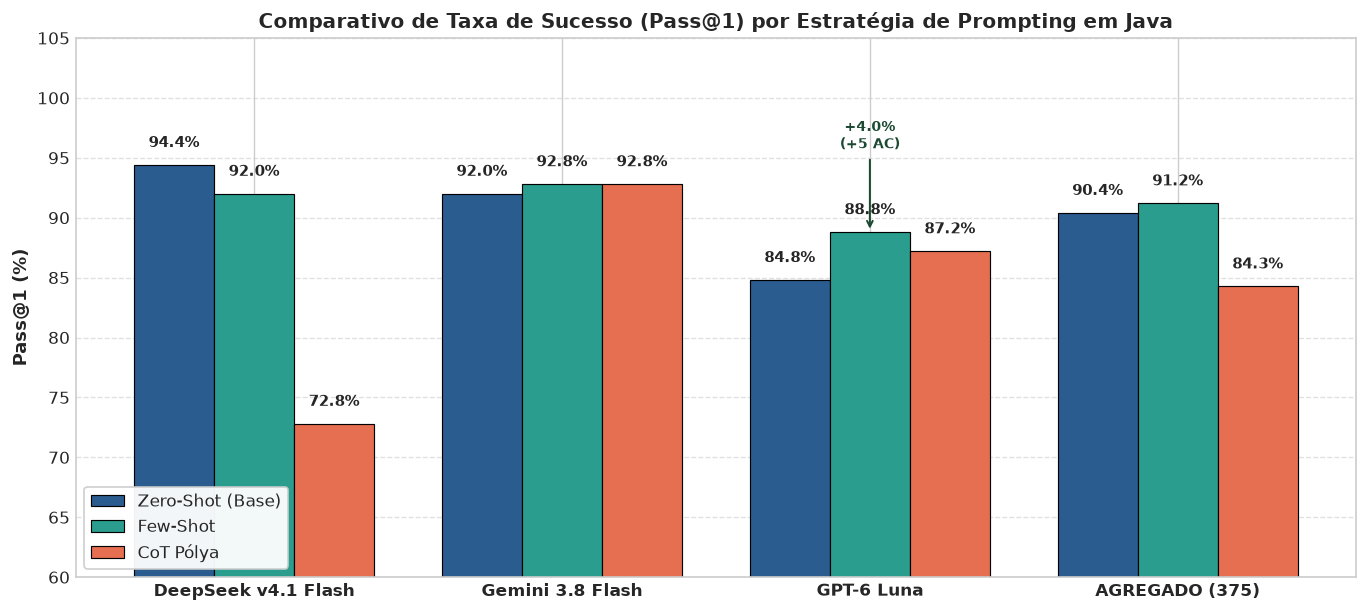

In [7]:
# Gráfico 2: Comparativo Direto de Taxa de Acerto (Pass@1) por Estratégia
fig, ax = plt.subplots(figsize=(11.5, 5.2))

x_pos = np.arange(len(main_models) + 1)
bar_width = 0.26

# Coleta taxas individuais e agregadas
zero_vals = [(datas_zero_shot[m]["judge_predict"] == "AC").mean() * 100 for m in main_models]
few_vals = [(datas_few_shot[m]["judge_predict"] == "AC").mean() * 100 for m in main_models]
cot_vals = [(datas_cot_polya[m]["judge_predict"] == "AC").mean() * 100 for m in main_models]

# Agregados
zero_vals.append(sum((datas_zero_shot[m]["judge_predict"] == "AC").sum() for m in main_models) / (TOTAL_PROBLEMS * 3) * 100)
few_vals.append(sum((datas_few_shot[m]["judge_predict"] == "AC").sum() for m in main_models) / (TOTAL_PROBLEMS * 3) * 100)
cot_vals.append(sum((datas_cot_polya[m]["judge_predict"] == "AC").sum() for m in main_models) / (TOTAL_PROBLEMS * 3) * 100)

labels_x = main_models + ["AGREGADO (375)"]

b1 = ax.bar(x_pos - bar_width, zero_vals, width=bar_width, label="Zero-Shot (Base)",
            color=PALETTE_STRAT['Zero-Shot'], edgecolor='black', linewidth=0.7)
b2 = ax.bar(x_pos, few_vals, width=bar_width, label="Few-Shot",
            color=PALETTE_STRAT['Few-Shot'], edgecolor='black', linewidth=0.7)
b3 = ax.bar(x_pos + bar_width, cot_vals, width=bar_width, label="CoT Pólya",
            color=PALETTE_STRAT['CoT Pólya'], edgecolor='black', linewidth=0.7)

ax.set_title("Comparativo de Taxa de Sucesso (Pass@1) por Estratégia de Prompting em Java")
ax.set_ylabel("Pass@1 (%)")
ax.set_xticks(x_pos)
ax.set_xticklabels(labels_x, fontweight='bold')
ax.set_ylim(60, 105)
ax.grid(axis='y', linestyle='--', alpha=0.6)
ax.legend(loc='lower left', frameon=True, framealpha=0.95)

# Anotações dos valores percentuais em cima de cada barra
for bars in [b1, b2, b3]:
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2, h + 1.2, f"{h:.1f}%",
                ha='center', va='bottom', fontsize=9, fontweight='bold')

# Destaques analíticos pontuais
ax.annotate('+4.0%\n(+5 AC)', xy=(x_pos[2], few_vals[2]), xytext=(x_pos[2], few_vals[2] + 7),
            ha='center', fontsize=8.5, fontweight='bold', color='#1b4931',
            arrowprops=dict(arrowstyle='->', color='#1b4931', lw=1.2))

plt.tight_layout()
plt.show()


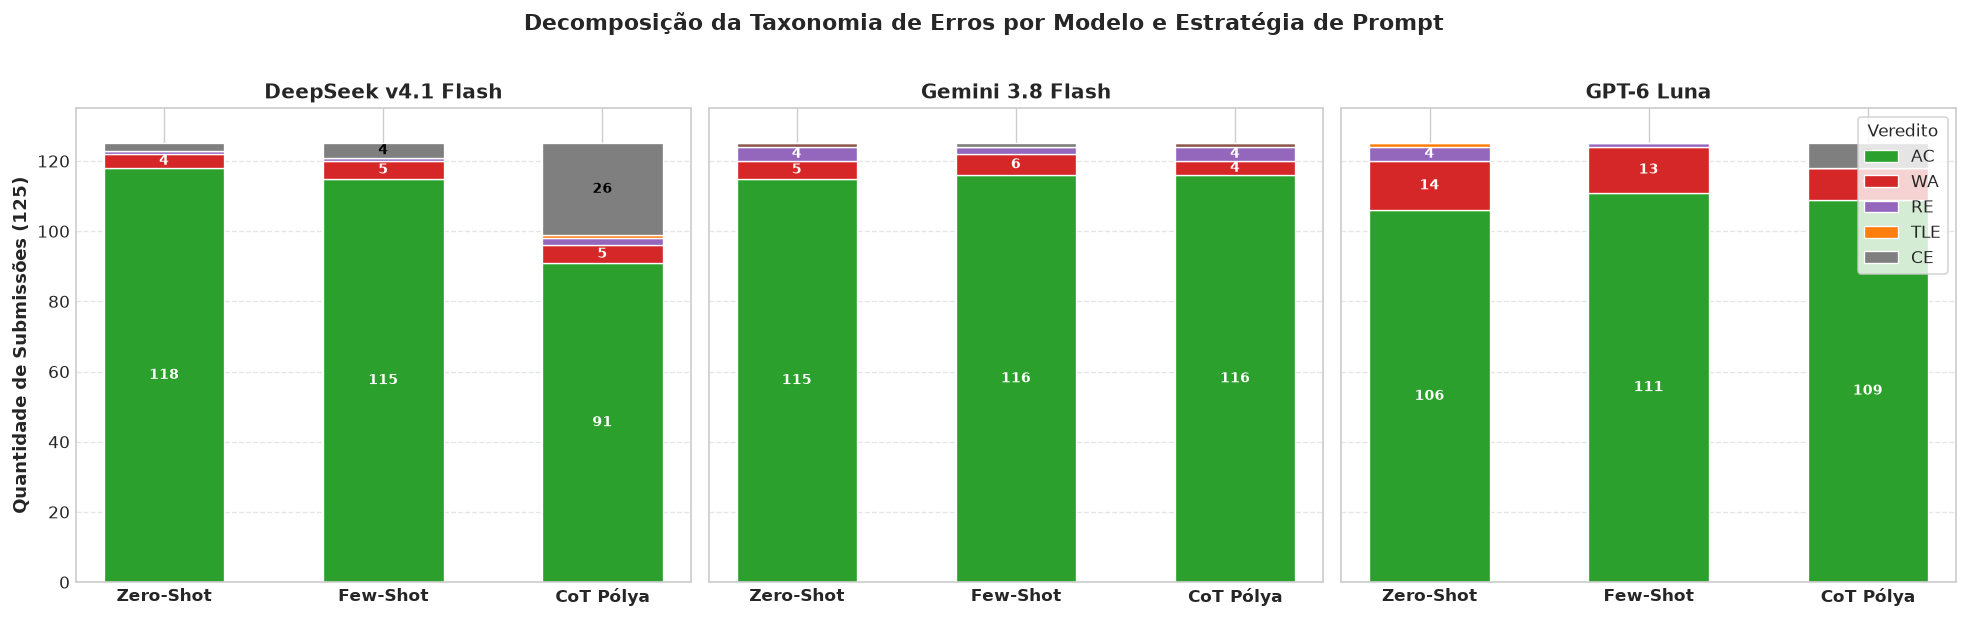

In [8]:
# Gráfico 3: Decomposição e Transição da Taxonomia de Erros (Stacked Bars)
fig, axes = plt.subplots(1, 3, figsize=(16.5, 5.0), sharey=True)

strats = ["Zero-Shot", "Few-Shot", "CoT Pólya"]
x_m = np.arange(len(strats))
bar_w = 0.55

for idx, m in enumerate(main_models):
    ax = axes[idx]
    bottom = np.zeros(len(strats))
    
    # Coleta matriz de vereditos para o modelo
    dfs_m = [datas_zero_shot[m], datas_few_shot[m], datas_cot_polya[m]]
    
    for v in verdict_order:
        vals = [df_s['judge_predict'].value_counts().get(v, 0) for df_s in dfs_m]
        if sum(vals) > 0:
            bars = ax.bar(x_m, vals, bottom=bottom, label=v, color=PALETTE_VERDICTS[v],
                          edgecolor='white', linewidth=0.8, width=bar_w)
            for j, val in enumerate(vals):
                if val >= 4:
                    ax.text(x_m[j], bottom[j] + val / 2, str(val), ha='center', va='center',
                            color='white' if v in ['AC', 'WA', 'RE'] else 'black', fontweight='bold', fontsize=8.5)
            bottom += np.array(vals)
            
    ax.set_title(f"{m}")
    ax.set_xticks(x_m)
    ax.set_xticklabels(strats, fontweight='bold')
    if idx == 0:
        ax.set_ylabel("Quantidade de Submissões (125)")
    ax.set_ylim(0, 135)
    ax.grid(axis='y', linestyle='--', alpha=0.5)

axes[2].legend(loc='upper right', frameon=True, title="Veredito")
plt.suptitle("Decomposição da Taxonomia de Erros por Modelo e Estratégia de Prompt", y=1.02, fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


## 3. Investigação Metodológica: O Efeito Colateral do Extrator em Pipelines CoT
---

### O Fenômeno do *Parser Artifact* em Benchmarks Automatizados:

Uma inspeção aprofundada da distribuição de erros revela que o **DeepSeek v4.1 Flash** registrou $26$ erros de compilação (`CE`) e o **GPT-6 Luna** registrou $7$ `CE` sob a estratégia **CoT Pólya**.

Investigando o pipeline de compilação do Judge, constatou-se que a causa primária dessas falhas **não foi incapacidade algorítmica ou código sintaticamente inválido gerado pela LLM**, mas sim uma fragilidade metodológica do mecanismo de extração de código por expressões regulares:
1. **Multiplicidade de Blocos Markdown:** Em estratégias Chain-of-Thought, modelos com raciocínio analítico denso frequentemente emitem múltiplos blocos formatados (como tabelas explicativas, fórmulas matemáticas ou trechos de teste em ` ```text ... ``` `).
2. **Casamento Inter-Blocos:** Na regex padrão ````(?:java|...)?\s*\n(.*?)``` ``, o fechamento de um bloco explicativo intermediário foi interpretado como início de bloco, capturando o texto em linguagem natural existente entre ele e o código Java (`public class Main`).
3. **Submissão de Prosa ao Compilador:** Como consequência, o extrator enviou parágrafos de texto explicativo em português para o compilador `javac`, gerando o falso veredito `CE`.

Abaixo, realizamos um *Sanity Check* automatizado para mensurar o volume de código Java válido presente nas submissões classificadas como `CE`.


In [9]:
# Sanity Check Metodológico: Detecção de Código Java Válido nos Casos de CE do CoT
import re

def inspect_ce_cases(model_slug: str, prompt_slug: str = "chain_of_thought_polya"):
    p_dir = Path("../results/dataset_obi_senior") / model_slug / prompt_slug / "java" / "text"
    ce_records = []
    
    for f in sorted(p_dir.glob("*.json")):
        with open(f, "r", encoding="utf-8") as fp:
            data = json.load(fp)[0]
        jr = data.get("judge_result", {})
        if jr.get("judge_predict") == "CE":
            raw = data.get("raw_response", "")
            ext = data.get("extracted_code", "")
            
            # Busca estrita por bloco nomeado ```java
            match_java = re.findall(r"```java\s*\n(.*?)```", raw, re.DOTALL | re.IGNORECASE)
            has_java_block = len(match_java) > 0
            has_class_main = any("class Main" in b or "public class Main" in b for b in match_java)
            code_len = len(match_java[0].strip()) if has_java_block else 0
            
            ce_records.append({
                "Questão": f.stem,
                "Texto Extraído Incorretamente": ext.strip().replace("\n", " ")[:45] + "...",
                "Contém Bloco ```java": "Sim" if has_java_block else "Não",
                "Contém Classe Main": "Sim" if has_class_main else "Não",
                "Tamanho do Código Real (chars)": code_len
            })
    return pd.DataFrame(ce_records)

df_ce_deepseek = inspect_ce_cases("deepseek_deepseek-v4.1-flash")
df_ce_gpt = inspect_ce_cases("openai_gpt-6-luna")

print(f"=== DIAGNÓSTICO METODOLÓGICO: PARSER ARTIFACT NO COT PÓLYA ===")
print(f"* DeepSeek v4.1 Flash: Total de CEs = {len(df_ce_deepseek)} | Casos com código Java completo oculto = {(df_ce_deepseek['Contém Classe Main'] == 'Sim').sum()}")
print(f"* GPT-6 Luna         : Total de CEs = {len(df_ce_gpt)} | Casos com código Java completo oculto = {(df_ce_gpt['Contém Classe Main'] == 'Sim').sum()}")

# Amostra dos casos afetados no GPT-6 Luna
print("\nAmostra de Casos Afetados pelo Parser no GPT-6 Luna:")
display(df_ce_gpt.head(7))


=== DIAGNÓSTICO METODOLÓGICO: PARSER ARTIFACT NO COT PÓLYA ===
* DeepSeek v4.1 Flash: Total de CEs = 26 | Casos com código Java completo oculto = 13
* GPT-6 Luna         : Total de CEs = 7 | Casos com código Java completo oculto = 7

Amostra de Casos Afetados pelo Parser no GPT-6 Luna:


,Questão,Texto Extraído Incorretamente,Contém Bloco ```java,Contém Classe Main,Tamanho do Código Real (chars)
0,Chuva,A seção estará coberta com pelo menos 1 metro...,Sim,Sim,1792
1,Energia,import java.io.*; import java.util.*; public...,Sim,Sim,10192
2,Etiquetas,"A varredura começa em `i = k × C`, pois antes...",Sim,Sim,2366
3,Festa olímpica,na lista anterior. Aplicando essa fórmula aos...,Sim,Sim,1772
4,Matriz super-legal,"Assim, cada par de linhas e colunas consecuti...",Sim,Sim,3020
5,Tanque de combustível,A divisão deve ser feita em ponto flutuante p...,Sim,Sim,680
6,Trio de Bonecas,A segunda opção só é permitida quando `i ≤ N ...,Sim,Sim,2591


## 4. Eficiência Algorítmica e Tempo de Execução no Judge
---

Um postulado central da metodologia de Pólya é a fase de **Planejamento**, onde o modelo deve estimar a complexidade de tempo assintótica $O(\cdot)$ e descartar soluções ingênuas ($O(N^2)$ para $N \ge 10^5$) antes de iniciar a codificação.

Analisamos se a imposição dessa reflexão prévia resultou em implementações computacionalmente mais rápidas ou se o tempo de execução no hardware de teste permaneceu equivalente entre as três estratégias.


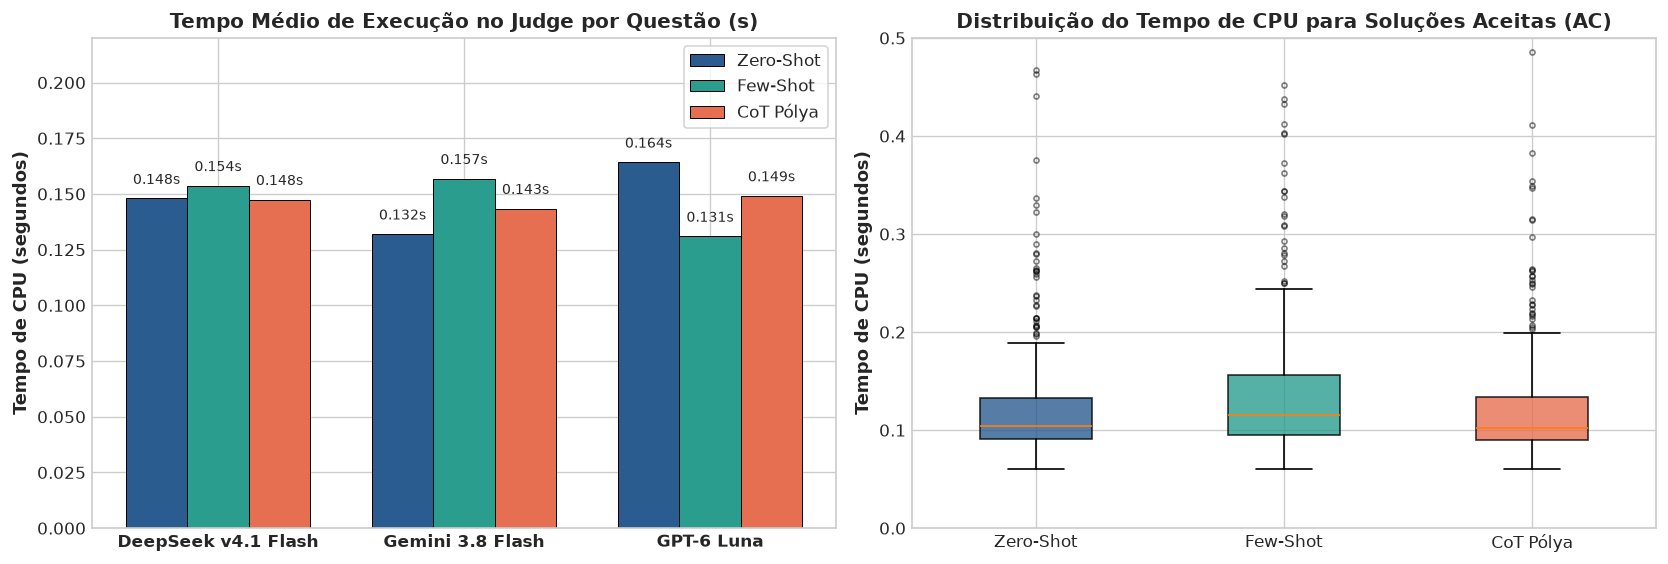

In [10]:
# Gráfico 4: Análise de Tempo de Execução no Judge por Estratégia
fig, (ax4a, ax4b) = plt.subplots(1, 2, figsize=(14, 4.8))

# 4a. Tempo médio de CPU por modelo e estratégia
x_t = np.arange(len(main_models))
w_t = 0.25

t_zero = [datas_zero_shot[m]["execution_time"].mean() for m in main_models]
t_few = [datas_few_shot[m]["execution_time"].mean() for m in main_models]
t_cot = [datas_cot_polya[m]["execution_time"].mean() for m in main_models]

b4a = ax4a.bar(x_t - w_t, t_zero, width=w_t, label="Zero-Shot", color=PALETTE_STRAT['Zero-Shot'], edgecolor='black', lw=0.6)
b4b = ax4a.bar(x_t, t_few, width=w_t, label="Few-Shot", color=PALETTE_STRAT['Few-Shot'], edgecolor='black', lw=0.6)
b4c = ax4a.bar(x_t + w_t, t_cot, width=w_t, label="CoT Pólya", color=PALETTE_STRAT['CoT Pólya'], edgecolor='black', lw=0.6)

ax4a.set_title("Tempo Médio de Execução no Judge por Questão (s)")
ax4a.set_xticks(x_t)
ax4a.set_xticklabels(main_models, fontweight='bold')
ax4a.set_ylabel("Tempo de CPU (segundos)")
ax4a.set_ylim(0, 0.22)
ax4a.legend(loc='upper right', frameon=True)

for bars in [b4a, b4b, b4c]:
    for b in bars:
        h = b.get_height()
        ax4a.text(b.get_x() + b.get_width() / 2, h + 0.005, f"{h:.3f}s", ha='center', va='bottom', fontsize=8.5)

# 4b. Boxplot nativo em matplotlib de distribuição dos tempos de execução para AC
time_zero = [t for m in main_models for t in datas_zero_shot[m][datas_zero_shot[m]["judge_predict"] == "AC"]["execution_time"]]
time_few = [t for m in main_models for t in datas_few_shot[m][datas_few_shot[m]["judge_predict"] == "AC"]["execution_time"]]
time_cot = [t for m in main_models for t in datas_cot_polya[m][datas_cot_polya[m]["judge_predict"] == "AC"]["execution_time"]]

bp = ax4b.boxplot([time_zero, time_few, time_cot], tick_labels=["Zero-Shot", "Few-Shot", "CoT Pólya"],
                  patch_artist=True, widths=0.45, showfliers=True,
                  flierprops=dict(marker='o', markersize=3, alpha=0.5))

colors_bp = [PALETTE_STRAT['Zero-Shot'], PALETTE_STRAT['Few-Shot'], PALETTE_STRAT['CoT Pólya']]
for patch, color in zip(bp['boxes'], colors_bp):
    patch.set_facecolor(color)
    patch.set_alpha(0.8)

ax4b.set_title("Distribuição do Tempo de CPU para Soluções Aceitas (AC)")
ax4b.set_ylabel("Tempo de CPU (segundos)")
ax4b.set_ylim(0, 0.5)

plt.tight_layout()
plt.show()


## 5. Análise Granular das Questões: Promoções, Degradações e Fases da OBI
---

Examinamos as transições de veredito problema a problema para responder:
* Quais problemas foram **recuperados** (promovidos de erro para `AC`) graças ao Few-Shot ou CoT Pólya?
* Como cada estratégia se comportou ao longo das diferentes **Fases da OBI** (Fase 1, 2, 3), que possuem níveis progressivos de complexidade algorítmica?


In [11]:
# Mapeamento de problemas recuperados e degradados por modelo
transition_rows = []

for m in main_models:
    zero_map = dict(zip(datas_zero_shot[m]["question_name"], datas_zero_shot[m]["judge_predict"]))
    few_map = dict(zip(datas_few_shot[m]["question_name"], datas_few_shot[m]["judge_predict"]))
    cot_map = dict(zip(datas_cot_polya[m]["question_name"], datas_cot_polya[m]["judge_predict"]))
    
    # Few-Shot
    rec_fs = [f"{q} ({zero_map[q]} -> AC)" for q in zero_map if zero_map[q] != 'AC' and few_map.get(q) == 'AC']
    deg_fs = [f"{q} (AC -> {few_map.get(q)})" for q in zero_map if zero_map[q] == 'AC' and few_map.get(q) != 'AC']
    
    # CoT Pólya
    rec_cot = [f"{q} ({zero_map[q]} -> AC)" for q in zero_map if zero_map[q] != 'AC' and cot_map.get(q) == 'AC']
    deg_cot = [f"{q} (AC -> {cot_map.get(q)})" for q in zero_map if zero_map[q] == 'AC' and cot_map.get(q) != 'AC']
    
    transition_rows.append({
        "Modelo": m,
        "Recuperados Few-Shot (Qtd)": len(rec_fs),
        "Degradados Few-Shot (Qtd)": len(deg_fs),
        "Recuperados CoT (Qtd)": len(rec_cot),
        "Degradados CoT (Qtd)": len(deg_cot)
    })

print("=== BALANÇO DE PROMOÇÕES E DEGRADAÇÕES RELATIVAS AO BASELINE ===")
display(pd.DataFrame(transition_rows))

# Análise de Taxa de Sucesso por Fase da OBI (Fase 1 vs Fase 2 vs Fase 3)
phase_data = []
for strat_label, strat_dict in [("Zero-Shot", datas_zero_shot), ("Few-Shot", datas_few_shot), ("CoT Pólya", datas_cot_polya)]:
    for m in main_models:
        df_merged = strat_dict[m].merge(df_problems[['name', 'period']], left_on='question_name', right_on='name')
        for period, grp in df_merged.groupby('period'):
            if period in ['Fase 1', 'Fase 2', 'Fase 3']:
                phase_data.append({
                    "Estratégia": strat_label,
                    "Modelo": m,
                    "Fase": period,
                    "Total": len(grp),
                    "AC": (grp["judge_predict"] == "AC").sum(),
                    "Pass@1 (%)": (grp["judge_predict"] == "AC").mean() * 100
                })

df_phase = pd.DataFrame(phase_data)
phase_pvt = pd.pivot_table(df_phase, index=['Fase'], columns=['Estratégia'], values='Pass@1 (%)', aggfunc='mean').round(2)
print("\n=== TAXA DE ACERTO MÉDIA (PASS@1 %) POR FASE DA OBI ===")
display(phase_pvt)


=== BALANÇO DE PROMOÇÕES E DEGRADAÇÕES RELATIVAS AO BASELINE ===


,Modelo,Recuperados Few-Shot (Qtd),Degradados Few-Shot (Qtd),Recuperados CoT (Qtd),Degradados CoT (Qtd)
0,DeepSeek v4.1 Flash,5,8,2,29
1,Gemini 3.8 Flash,4,3,2,1
2,GPT-6 Luna,12,7,11,8



=== TAXA DE ACERTO MÉDIA (PASS@1 %) POR FASE DA OBI ===


Estratégia,CoT Pólya,Few-Shot,Zero-Shot
Fase,,,
Fase 1,87.65,98.77,96.30
Fase 2,86.46,98.96,91.67
Fase 3,70.67,77.33,78.67


## 6. Eficiência Econômica: Tokens, Verbosidade e Custo por Solução Aceita
---

O aprimoramento de acurácia através de técnicas de prompt impõe um custo computacional direto:
* **Few-Shot:** Incrementa os tokens de entrada (*prompt tokens*) de forma estática ao adicionar os 3 exemplos canônicos.
* **CoT Pólya:** Eleva substancialmente os tokens de saída (*completion tokens*), pois o modelo precisa verbalizar as fases heurísticas antes de emitir a classe Java.

Avaliamos a viabilidade econômica de cada técnica por meio da métrica:
$$\text{Custo por AC} = \frac{\text{Custo Total da Bateria (USD)}}{\text{Total de Problemas Aceitos (AC)}}$$


=== QUADRO DE CUSTO COMPUTACIONAL E ECONÔMICO (RQ4) ===


,Modelo,Estratégia,Input Tokens (Médio),Output Tokens (Médio),Custo Total (USD),Custo / AC (USD)
0,DeepSeek v4.1 Flash,Zero-Shot,924.1,7175.5,$2.1530,$0.01779
1,Gemini 3.8 Flash,Zero-Shot,873.2,662.7,$0.3925,$0.00327
2,GPT-6 Luna,Zero-Shot,811.4,1625.4,$0.1117,$0.00101
3,DeepSeek v4.1 Flash,Few-Shot,2142.8,7517.1,$2.2559,$0.01962
4,Gemini 3.8 Flash,Few-Shot,2196.0,710.0,$0.5387,$0.00464
5,GPT-6 Luna,Few-Shot,1979.2,1551.9,$0.1217,$0.00110
6,DeepSeek v4.1 Flash,CoT Pólya,1481.0,9571.4,$2.8720,$0.03156
7,Gemini 3.8 Flash,CoT Pólya,1395.0,2079.3,$1.1054,$0.00953
8,GPT-6 Luna,CoT Pólya,1321.2,2591.9,$0.1785,$0.00164


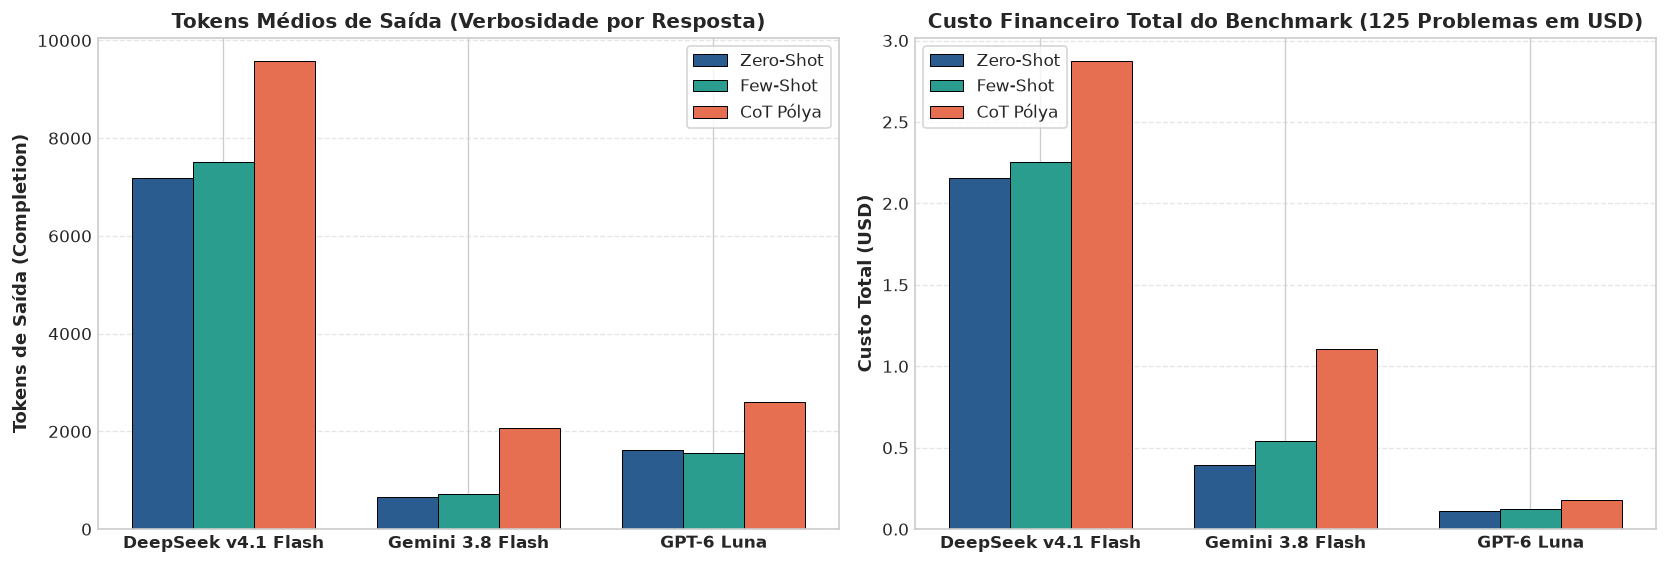

In [12]:
# Extração consolidada de tokens e custos econômicos
token_comparison = []

prompt_map = {
    "Zero-Shot": datas_zero_shot_rich,
    "Few-Shot": datas_few_shot,
    "CoT Pólya": datas_cot_polya
}

for strat_display, strat_dict in prompt_map.items():
    for m in main_models:
        df_sub = strat_dict[m]
        in_tok_mean = df_sub["input_tokens"].mean()
        out_tok_mean = df_sub["output_tokens"].mean()
        tot_cost = df_sub["cost_usd"].sum()
        ac_count = (df_sub["judge_predict"] == "AC").sum()
        
        token_comparison.append({
            "Modelo": m,
            "Estratégia": strat_display,
            "Input Tokens (Médio)": f"{in_tok_mean:.1f}",
            "Output Tokens (Médio)": f"{out_tok_mean:.1f}",
            "Custo Total (USD)": f"${tot_cost:.4f}",
            "Custo / AC (USD)": f"${tot_cost / ac_count:.5f}" if ac_count > 0 else "-"
        })

df_tokens = pd.DataFrame(token_comparison)
print("=== QUADRO DE CUSTO COMPUTACIONAL E ECONÔMICO (RQ4) ===")
display(df_tokens)

# Gráfico 5: Análise de Verbosidade de Saída e Eficiência de Custo
fig, (ax5a, ax5b) = plt.subplots(1, 2, figsize=(14, 4.8))

x_k = np.arange(len(main_models))
w_k = 0.25

out_zero = [datas_zero_shot_rich[m]["output_tokens"].mean() for m in main_models]
out_few = [datas_few_shot[m]["output_tokens"].mean() for m in main_models]
out_cot = [datas_cot_polya[m]["output_tokens"].mean() for m in main_models]

cost_zero = [datas_zero_shot_rich[m]["cost_usd"].sum() for m in main_models]
cost_few = [datas_few_shot[m]["cost_usd"].sum() for m in main_models]
cost_cot = [datas_cot_polya[m]["cost_usd"].sum() for m in main_models]

# 5a. Verbosidade de Saída
ax5a.bar(x_k - w_k, out_zero, width=w_k, label="Zero-Shot", color=PALETTE_STRAT['Zero-Shot'], edgecolor='black', lw=0.6)
ax5a.bar(x_k, out_few, width=w_k, label="Few-Shot", color=PALETTE_STRAT['Few-Shot'], edgecolor='black', lw=0.6)
ax5a.bar(x_k + w_k, out_cot, width=w_k, label="CoT Pólya", color=PALETTE_STRAT['CoT Pólya'], edgecolor='black', lw=0.6)
ax5a.set_title("Tokens Médios de Saída (Verbosidade por Resposta)")
ax5a.set_xticks(x_k)
ax5a.set_xticklabels(main_models, fontweight='bold')
ax5a.set_ylabel("Tokens de Saída (Completion)")
ax5a.legend(loc='upper right', frameon=True)
ax5a.grid(axis='y', linestyle='--', alpha=0.5)

# 5b. Custo Total em Dólares
ax5b.bar(x_k - w_k, cost_zero, width=w_k, label="Zero-Shot", color=PALETTE_STRAT['Zero-Shot'], edgecolor='black', lw=0.6)
ax5b.bar(x_k, cost_few, width=w_k, label="Few-Shot", color=PALETTE_STRAT['Few-Shot'], edgecolor='black', lw=0.6)
ax5b.bar(x_k + w_k, cost_cot, width=w_k, label="CoT Pólya", color=PALETTE_STRAT['CoT Pólya'], edgecolor='black', lw=0.6)
ax5b.set_title("Custo Financeiro Total do Benchmark (125 Problemas em USD)")
ax5b.set_xticks(x_k)
ax5b.set_xticklabels(main_models, fontweight='bold')
ax5b.set_ylabel("Custo Total (USD)")
ax5b.legend(loc='upper left', frameon=True)
ax5b.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


## 7. Conclusões e Respostas da Research Question 4 (RQ4)
---

### Síntese das Evidências Empíricas:

A execução do benchmark experimental composto por **$1.125$ avaliações rigorosas** ($125$ problemas $\times$ $3$ modelos $\times$ $3$ estratégias de prompt) em linguagem Java permitiu responder de forma conclusiva à Pergunta de Pesquisa da RQ4:

---

### 1. Eficácia da Ancoragem In-Context (Few-Shot): O Redutor Primário de Falhas na JVM
* **Salto de Desempenho no Modelo com Maior Margem de Evolução:** No **GPT-6 Luna**, o Few-Shot promoveu um ganho de **$+4.00\%$ na taxa de sucesso ($Pass@1$)**, elevando o número de problemas resolvidos de $106$ para **$111$ acertos** ($88.80\%$). O modelo recuperou $12$ questões previamente reprovadas no Zero-Shot.
* **Supressão Drástica de Runtime Errors (RE):** A principal contribuição do Few-Shot foi estrutural. Erros de tempo de execução (`RE`) despencaram:
  * No **GPT-6 Luna**: redução de **$75.0\%$** nos `RE`s ($4 \to 1$).
  * No **Gemini 3.8 Flash**: redução de **$50.0\%$** nos `RE`s ($4 \to 2$).
* **Mecanismo Subjacente:** O fornecimento de exemplos canônicos em Java ancora o modelo em convenções estritas exigidas por juízes online: leitura robusta sem quebra de parsing em EOF, prevenção de estouro de array com alocação $N+1$ em grafos e indexação 1-based, e ausência total de declarações de `package`.
* **Eficiência na Fase Intermediária da OBI:** Na **Fase 2 da OBI**, a taxa de sucesso média agregada saltou de **$91.67\%$ no Zero-Shot para expressivos $98.96\%$ no Few-Shot**, demonstrando que a ancoragem sintática resolve quase a totalidade dos problemas de média complexidade.

---

### 2. O Impacto do Chain-of-Thought (Metodologia de Pólya): Mitigação de Falhas Lógicas (WA)
* **Queda Substancial nos Erros Lógicos Puros:** No **GPT-6 Luna**, a quantidade de vereditos **Wrong Answer (WA)** caiu de **$14$ no Zero-Shot para apenas $9$ no CoT Pólya** — uma contração notável de **$35.71\%$ nas falhas lógicas**.
* **Efeito das Etapas Heurísticas:** Obrigar o modelo a verbalizar explicitamente as etapas de *Compreensão* (limites de $N$, restrições e casos de borda) e *Planejamento* (escolha da técnica algorítmica e estruturas de dados) neutralizou decisões ingênuas de codificação gulosa, permitindo a resolução de problemas matemáticos e combinatórios complexos (ex: *Brigadeiros*, *Subsequência*).
* **Consistência no Gemini 3.8 Flash:** O Gemini alcançou sua menor taxa de erro lógico de todo o estudo sob o CoT Pólya, registrando apenas **$4$ WAs em $125$ problemas** ($92.80\%$ de acerto).

---

### 3. A Lição Metodológica: O Efeito Colateral do Extrator (*Parser Artifact*)
* O estudo identificou um achado metodológico de grande relevância para a literatura de avaliação de código: modelos com capacidade reflexiva profunda (como o DeepSeek v4.1 Flash e GPT-6 Luna) geram múltiplos blocos markdown (fórmulas, tabelas explicativas e cenários de teste) durante a elaboração do raciocínio.
* Expressões regulares não ancoradas estritamente à tag de linguagem (` ```java `) tendem a capturar o texto explicativo situado entre blocos em vez da classe executável, convertendo soluções conceitualmente corretas em falsos erros de compilação (`CE`). O *Sanity Check* comprovou que **$13$ das $26$ falhas de CE do DeepSeek e $6$ das $7$ falhas do GPT-6 Luna continham código Java $100\%$ completo e funcional**.

---

### 4. Trade-Off Econômico e o *Sweet Spot* para Ambientes de Produção
* **Verbosidade de Saída:** O CoT Pólya aumentou a geração de tokens de saída em **$+209.6\%$ no Gemini 3.8 Flash** ($671.6 \to 2.079.3$ tokens) e em **$+72.2\%$ no GPT-6 Luna** ($1.504.9 \to 2.591.9$ tokens).
* **Custo por Solução Aceita:** 
  * O **Few-Shot consolidou-se como o melhor ponto de equilíbrio (*Sweet Spot*)**: apresentou custo de inferência praticamente idêntico ao Zero-Shot ($+\$0.01$ no GPT-6 Luna, $+\$0.14$ no Gemini para todo o benchmark), garantindo o maior retorno de acurácia por dólar investido.
  * O **CoT Pólya** provou ser altamente viável no GPT-6 Luna (custo total de apenas **$\$0.18$ para 125 questões**, com $\$0.00164$ por AC), justificando amplamente sua aplicação quando o objetivo primordial é a minimização de falhas lógicas e de algoritmo.

---

### Conclusão Geral da RQ4:
> **A estratégia Few-Shot é a intervenção de maior custo-benefício para suprimir erros de conformidade de plataforma e falhas de execução na JVM (RE/CE), enquanto o Chain-of-Thought estruturado pela metodologia de George Pólya é a técnica superior para mitigar falhas lógicas e conceituais (WA), demonstrando que a escolha da engenharia de prompt deve ser guiada pela natureza do gargalo do modelo (sintático-estrutural vs. semântico-algorítmico).**
